In [1]:
from tensorflow.keras.layers import Input, Lambda, Dense, Flatten,Conv2D
from tensorflow.keras.models import Model
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img
from tensorflow.keras.models import Sequential
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

In [3]:
IMAGE_SIZE=[224,224]
train_path="Dataset/Train"
test_path="Dataset/Test"

In [5]:
mobilenet=VGG19(input_shape=IMAGE_SIZE +[3],weights='imagenet',include_top=False)

In [7]:
for layer in mobilenet.layers:
    layer.trainable=False

In [8]:
folders=glob("Dataset/Train/*")

In [9]:
folders

['Dataset/Train\\Parasite', 'Dataset/Train\\Uninfected']

In [10]:
x=Flatten()(mobilenet.output)
prediction=Dense(len(folders),activation='softmax')(x)

model=Model(inputs=mobilenet.input,outputs=prediction)

In [11]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [15]:

from tensorflow.keras.layers import MaxPooling2D


In [20]:
model=Sequential()
model.add(Conv2D(filters=16,kernel_size=2,padding='same',activation='relu',input_shape=(224,224,3)))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=32,kernel_size=2,padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=32,kernel_size=2,padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Flatten())
model.add(Dense(500,activation='relu'))
model.add(Dense(2,activation='softmax'))
model.summary()


Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 224, 224, 16)      208       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 112, 112, 16)     0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 112, 112, 32)      2080      
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 56, 56, 32)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 56, 56, 32)        4128      
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 28, 28, 32)      

In [21]:
model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  metrics=['accuracy']
)

In [23]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen=ImageDataGenerator(rescale=1/255,
                                shear_range=0.2,
                                zoom_range=.2,
                                horizontal_flip=True)
test_datagen=ImageDataGenerator(rescale=1/255)

In [24]:
training_set=train_datagen.flow_from_directory("Dataset/Train",target_size=(224,224),batch_size=32,class_mode='categorical')

Found 416 images belonging to 2 classes.


In [25]:
test_set=test_datagen.flow_from_directory("Dataset/Test",target_size=(224,224),batch_size=32,class_mode='categorical')

Found 134 images belonging to 2 classes.


In [26]:
r=model.fit_generator(
    training_set,
    validation_data=test_set,
    epochs=50,
    steps_per_epoch=len(training_set),
    validation_steps=len(test_set)
    
    
)

C:\Users\HP\AppData\Local\Temp\ipykernel_13176\1289906725.py:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  r=model.fit_generator(


Epoch 1/50
13/13 [==============================] - 22s 2s/step - loss: 1.6381 - accuracy: 0.5312 - val_loss: 0.7936 - val_accuracy: 0.3657
Epoch 2/50
13/13 [==============================] - 18s 1s/step - loss: 0.5681 - accuracy: 0.7236 - val_loss: 0.8341 - val_accuracy: 0.4030
Epoch 3/50
13/13 [==============================] - 27s 2s/step - loss: 0.4464 - accuracy: 0.8173 - val_loss: 1.0330 - val_accuracy: 0.4328
Epoch 4/50
13/13 [==============================] - 23s 2s/step - loss: 0.4399 - accuracy: 0.7933 - val_loss: 0.8160 - val_accuracy: 0.5597
Epoch 5/50
13/13 [==============================] - 26s 2s/step - loss: 0.3531 - accuracy: 0.8750 - val_loss: 0.7543 - val_accuracy: 0.5672
Epoch 6/50
13/13 [==============================] - 29s 2s/step - loss: 0.2643 - accuracy: 0.8846 - val_loss: 0.4853 - val_accuracy: 0.7239
Epoch 7/50
13/13 [==============================] - 35s 3s/step - loss: 0.2210 - accuracy: 0.9255 - val_loss: 0.6373 - val_accuracy: 0.6791
Epoch 8/50
13/13 [==

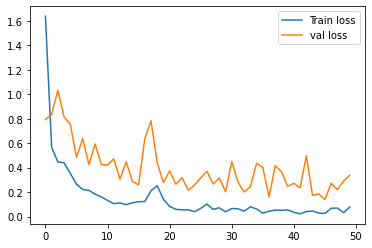

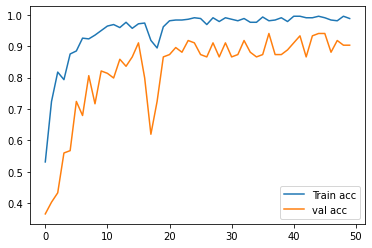

In [29]:
plt.plot(r.history['loss'],label='Train loss')
plt.plot(r.history['val_loss'],label='val loss')

plt.legend()
plt.show()

plt.plot(r.history['accuracy'],label='Train acc')
plt.plot(r.history['val_accuracy'],label='val acc')

plt.legend()
plt.show()

In [ ]:
from tensorflow.keras.models import load_model

In [34]:
model.save('model_vgg19.h5')

In [36]:
y_pred=model.predict(test_set)

5/5 [==============================] - 1s 198ms/step


In [37]:
y_pred

array([[1.00000000e+00, 7.75851144e-14],
       [1.00000000e+00, 0.00000000e+00],
       [9.99999285e-01, 6.98584074e-07],
       [6.27600311e-05, 9.99937177e-01],
       [6.13040090e-01, 3.86959881e-01],
       [1.00000000e+00, 1.53312446e-10],
       [1.00000000e+00, 2.06081812e-14],
       [1.00000000e+00, 3.71485937e-13],
       [1.00000000e+00, 7.26757365e-09],
       [1.93831652e-01, 8.06168318e-01],
       [1.20215339e-03, 9.98797774e-01],
       [1.00000000e+00, 3.10993037e-10],
       [9.89687860e-01, 1.03121642e-02],
       [2.20758913e-04, 9.99779284e-01],
       [6.66332344e-05, 9.99933362e-01],
       [1.00000000e+00, 0.00000000e+00],
       [1.00000000e+00, 2.95504510e-10],
       [1.00000000e+00, 1.09039687e-12],
       [3.07805706e-02, 9.69219446e-01],
       [8.33043456e-03, 9.91669536e-01],
       [1.02000812e-03, 9.98979986e-01],
       [3.98095988e-04, 9.99601901e-01],
       [1.00000000e+00, 2.70264156e-20],
       [9.84090507e-01, 1.59094911e-02],
       [3.871361

In [38]:
import numpy as np
y_pred=np.argmax(y_pred,axis=1)

In [79]:
len(y_pred)

134

In [40]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image

In [55]:
model=load_model('model_vgg19.h5')

In [80]:
img=image.load_img('Dataset/Test/Parasite/C39P4thinF_original_IMG_20150622_105554_cell_12.png',target_size=(224,224))


In [81]:
x=image.img_to_array(img)
x

array([[[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       ...,

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]]], dtype=float32)

In [82]:
x.shape

(224, 224, 3)

In [83]:
x=x/255

In [84]:
x=np.expand_dims(x,axis=0)
img_data=preprocess_input(x)
img_data.shape

(1, 224, 224, 3)

In [85]:
model.predict(img_data)

1/1 [==============================] - 0s 34ms/step


array([[0., 1.]], dtype=float32)

In [86]:
a=np.argmax(model.predict(img_data),axis=1)

1/1 [==============================] - 0s 37ms/step


In [87]:
if(a==1):
    print("Uninfected")
else:
    print("infected")

Uninfected
